In [1]:
!pip install umap-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib import colors
import seaborn as sns
from sklearn.datasets import make_classification, make_blobs, make_moons
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.manifold import MDS, Isomap, SpectralEmbedding, LocallyLinearEmbedding, TSNE
from sklearn.preprocessing import StandardScaler, MinMaxScaler

from sklearn.cluster import KMeans, DBSCAN
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots


import warnings
warnings.filterwarnings('ignore')


try:
    import umap  # pip install umap-learn
    HAS_UMAP = True
except ImportError:
    HAS_UMAP = False

In [3]:
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = [12, 8]
plt.rcParams['figure.dpi'] = 100


In [4]:
from multidim_visualization import HighDimVisualizer

In [5]:
df = pd.read_csv('/content/ObesityDataSet.csv')


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF                             21

In [7]:
df.head(5)

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [8]:
df.describe()

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000
mean,24.312600,1.701677,86.586058,2.419043,2.685628,2.008011,1.010298,0.657866
std,6.345968,0.093305,26.191172,0.533927,0.778039,0.612953,0.850592,0.608927
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.947192,1.630000,65.473343,2.000000,2.658738,1.584812,0.124505,0.000000
50%,22.777890,1.700499,83.000000,2.385502,3.000000,2.000000,1.000000,0.625350
75%,26.000000,1.768464,107.430682,3.000000,3.000000,2.477420,1.666678,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


In [9]:
df['NObeyesdad'].value_counts()

,count
NObeyesdad,
Obesity_Type_I,351
Obesity_Type_III,324
Obesity_Type_II,297
Overweight_Level_I,290
Overweight_Level_II,290
Normal_Weight,287
Insufficient_Weight,272


Классы (3): ['Obesity_Type_I' 'Obesity_Type_II' 'Obesity_Type_III']

Информация о данных:
  Размер: (972, 22)
  Количество классов: 3
  Количество признаков: 22
  Минимум: -2.967, Максимум: 4.428
  Среднее: 0.239, Стандартное отклонение: 0.739
ПОЛНАЯ ВИЗУАЛИЗАЦИЯ МНОГОМЕРНЫХ ДАННЫХ

1. Парные диаграммы рассеяния (PairPlot)


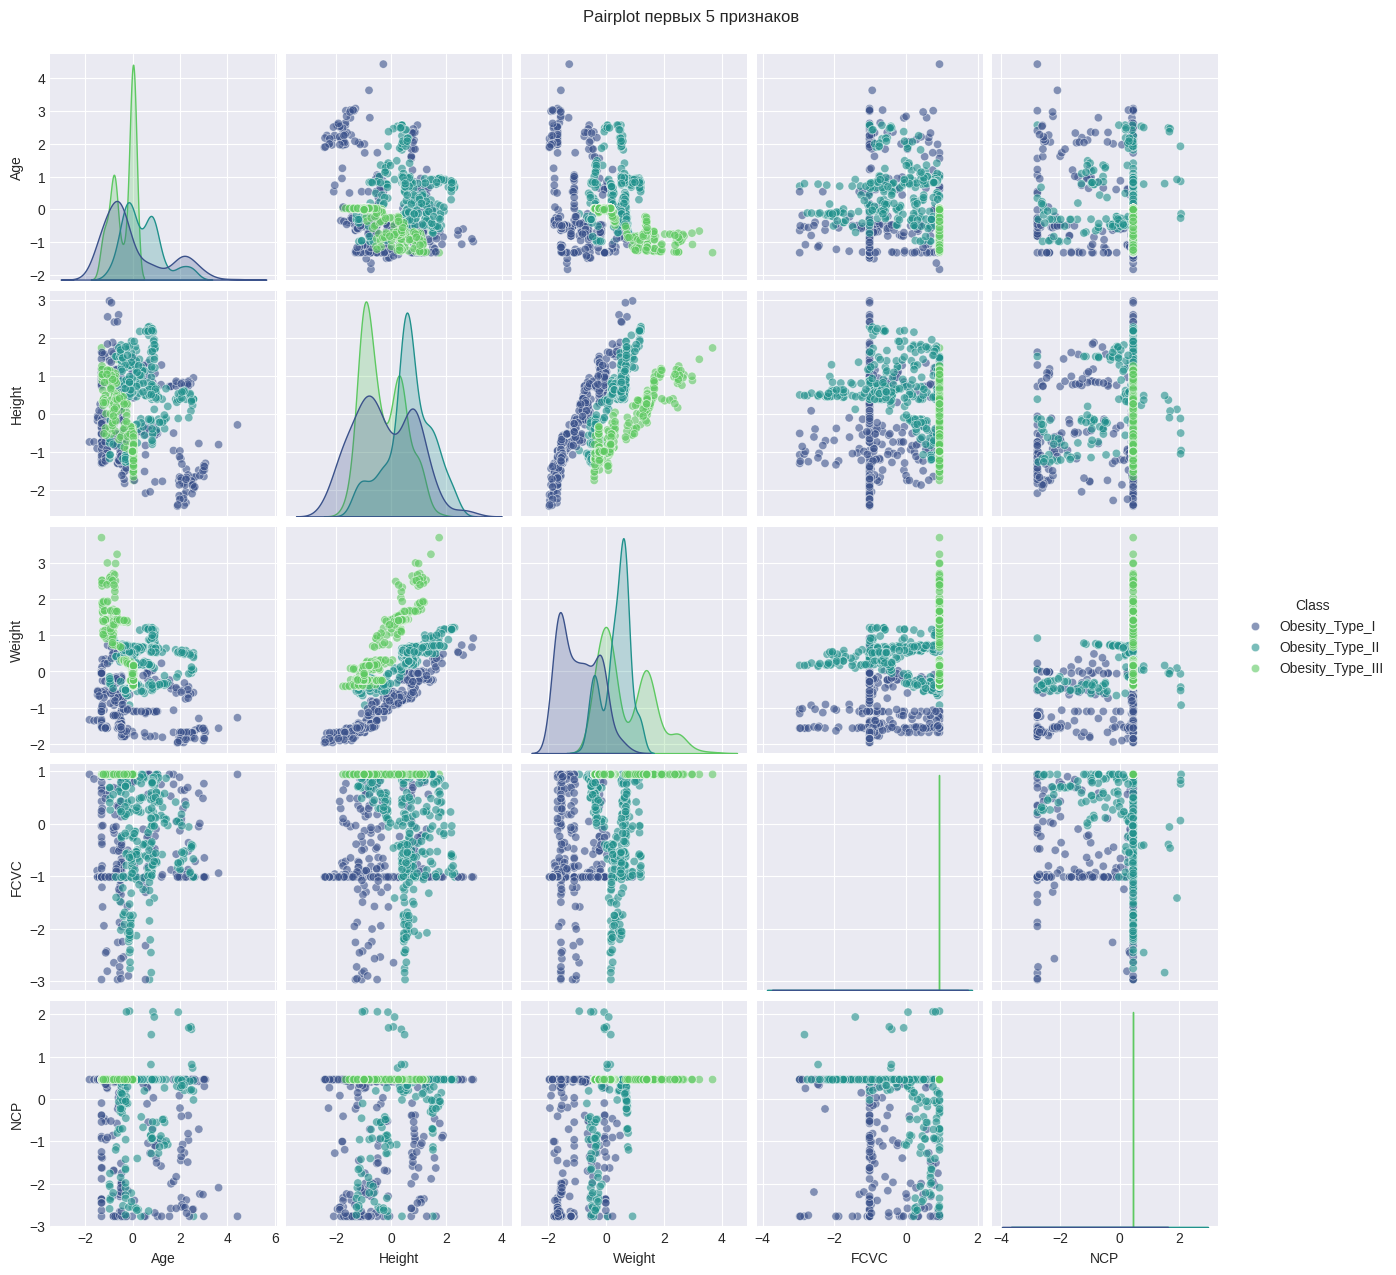


2. Тепловая карта корреляций


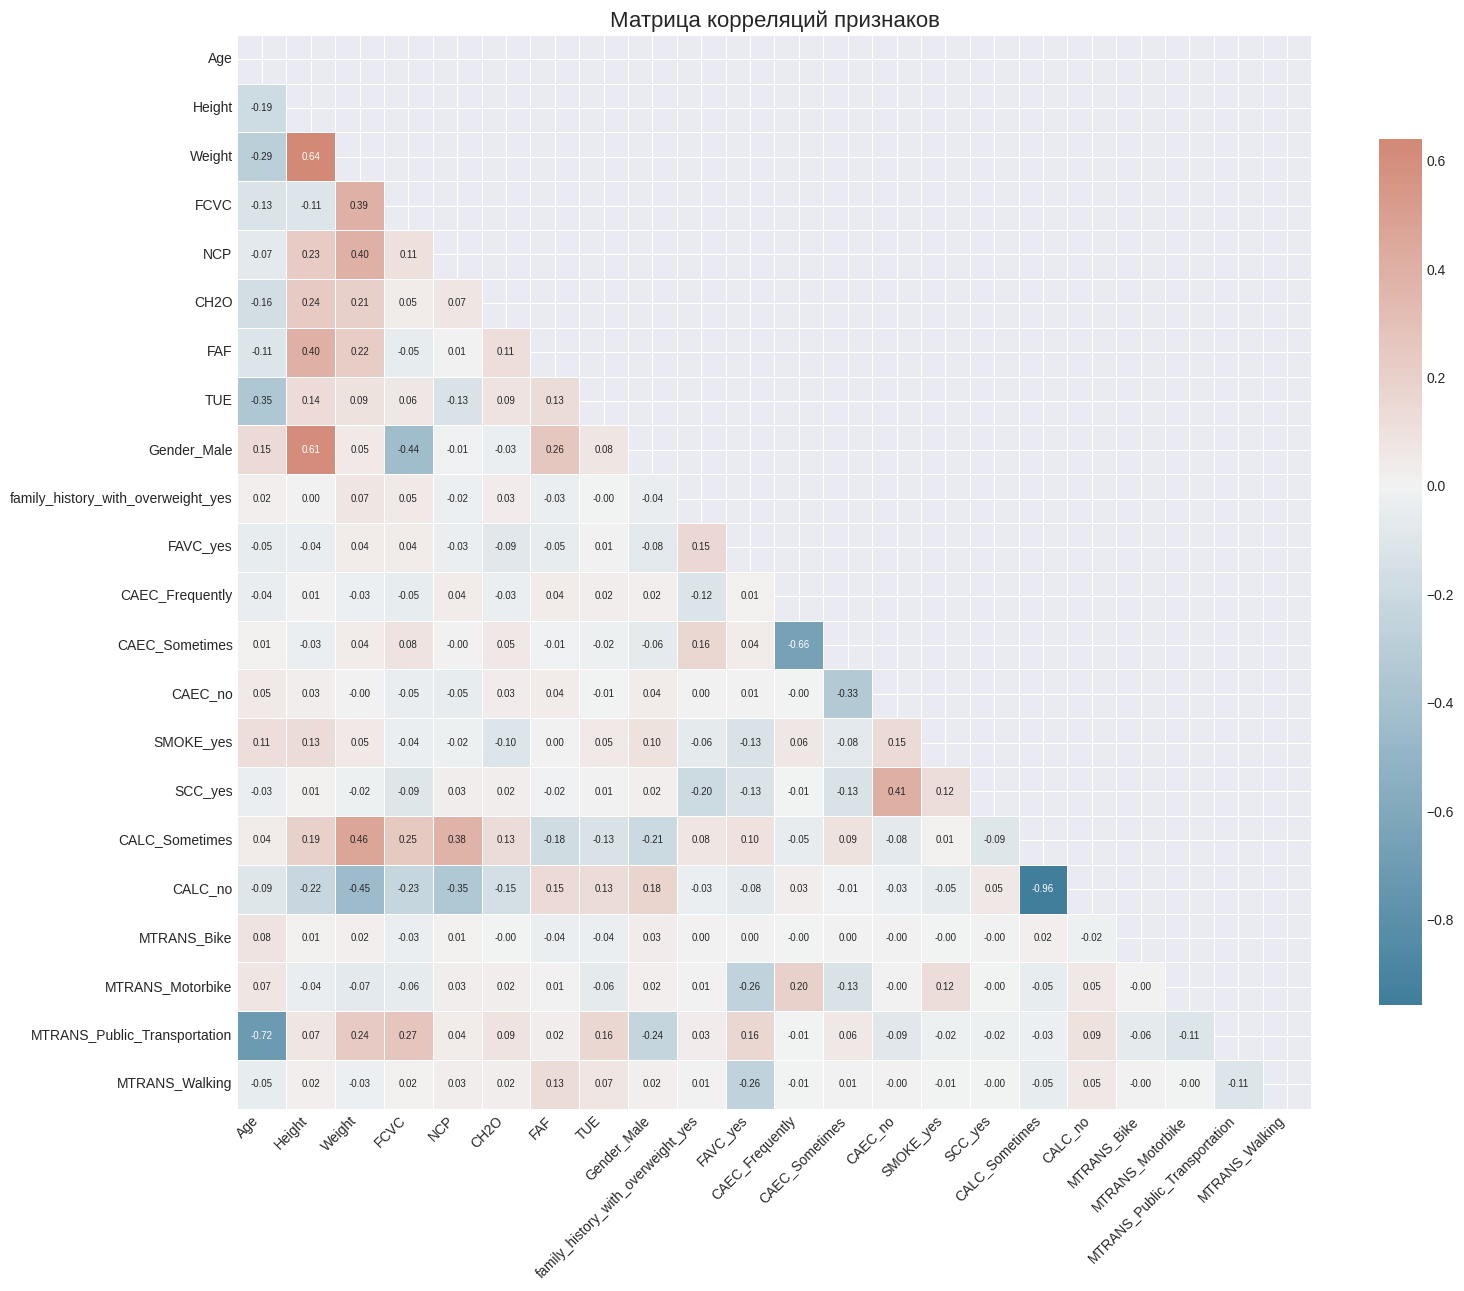


3. Визуализация PCA (2D и 3D)
Объясненная дисперсия: [0.27168079 0.16325256 0.15307229]
Суммарная объясненная дисперсия: 0.588


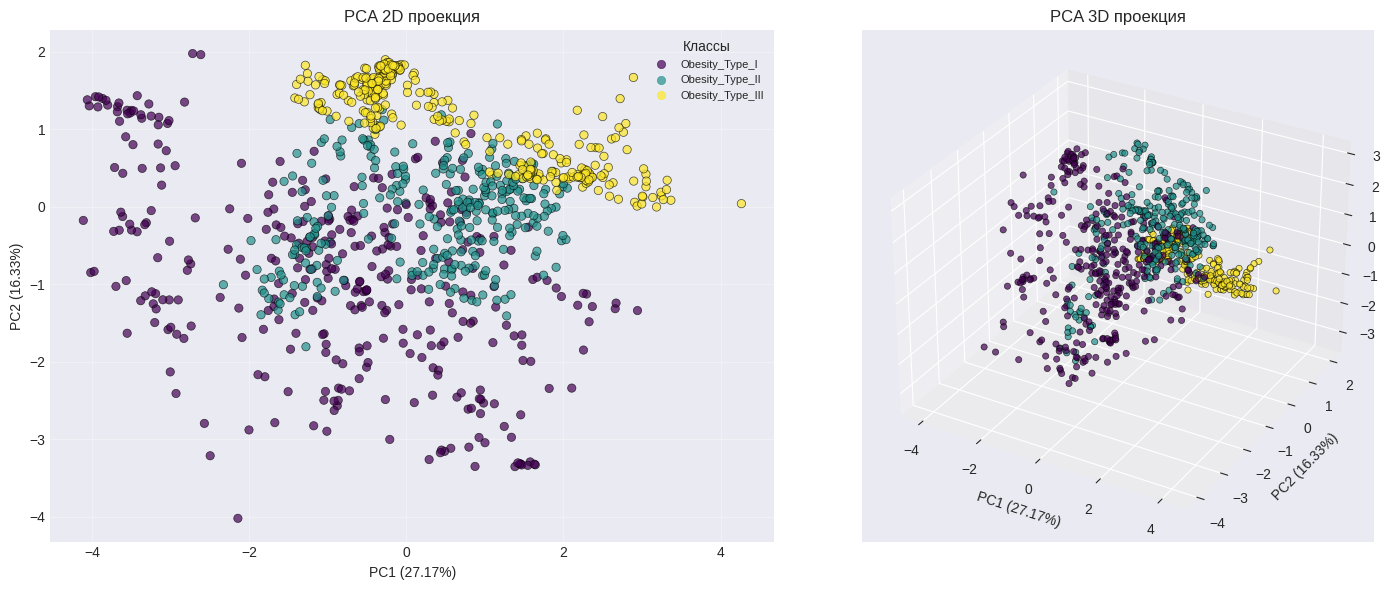

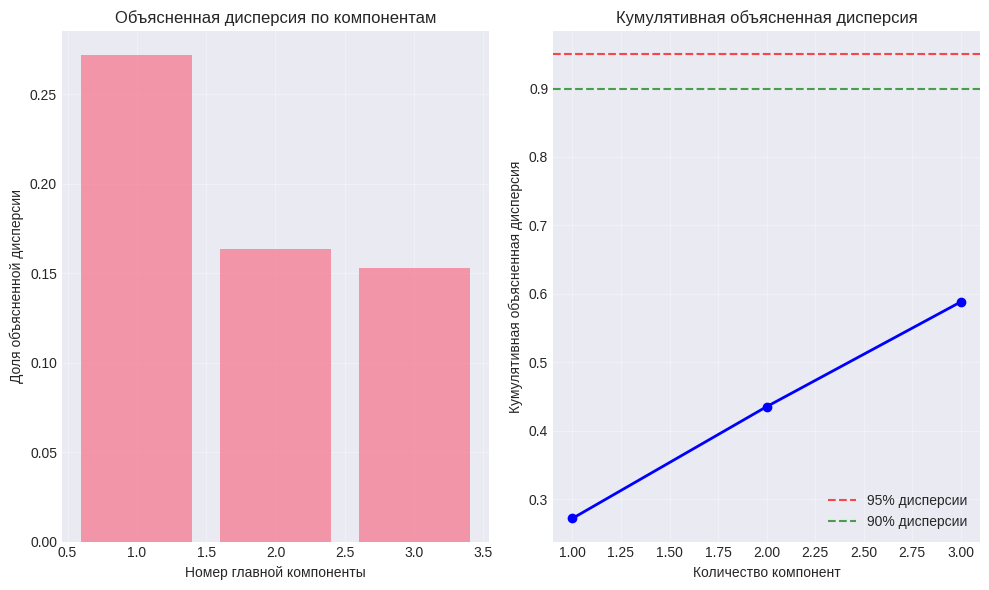


4. Визуализация t-SNE
  Используем исходные данные (22 признаков)
  Вычисляем t-SNE с perplexity=5...
  Вычисляем t-SNE с perplexity=30...
  Вычисляем t-SNE с perplexity=50...


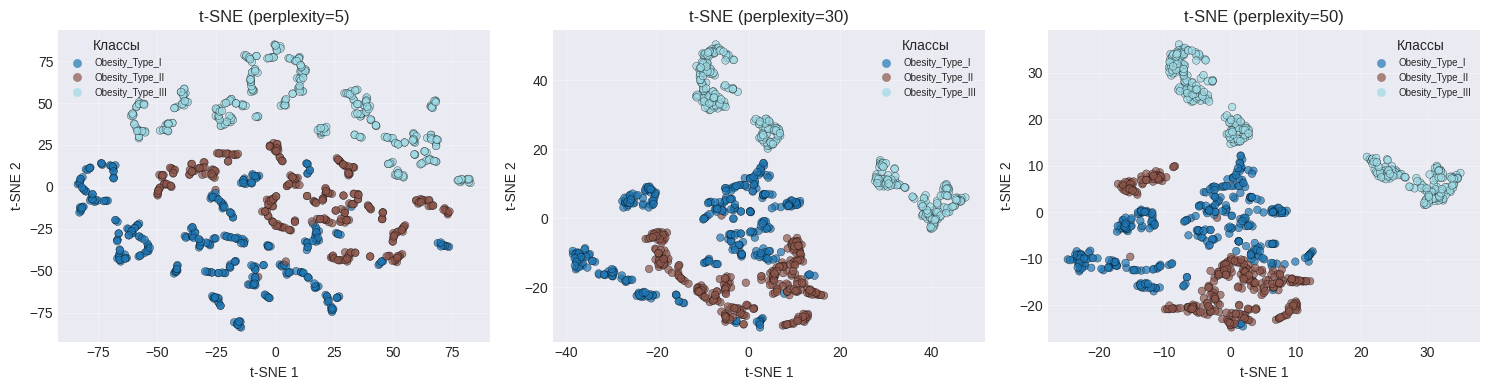


6. Параллельные координаты


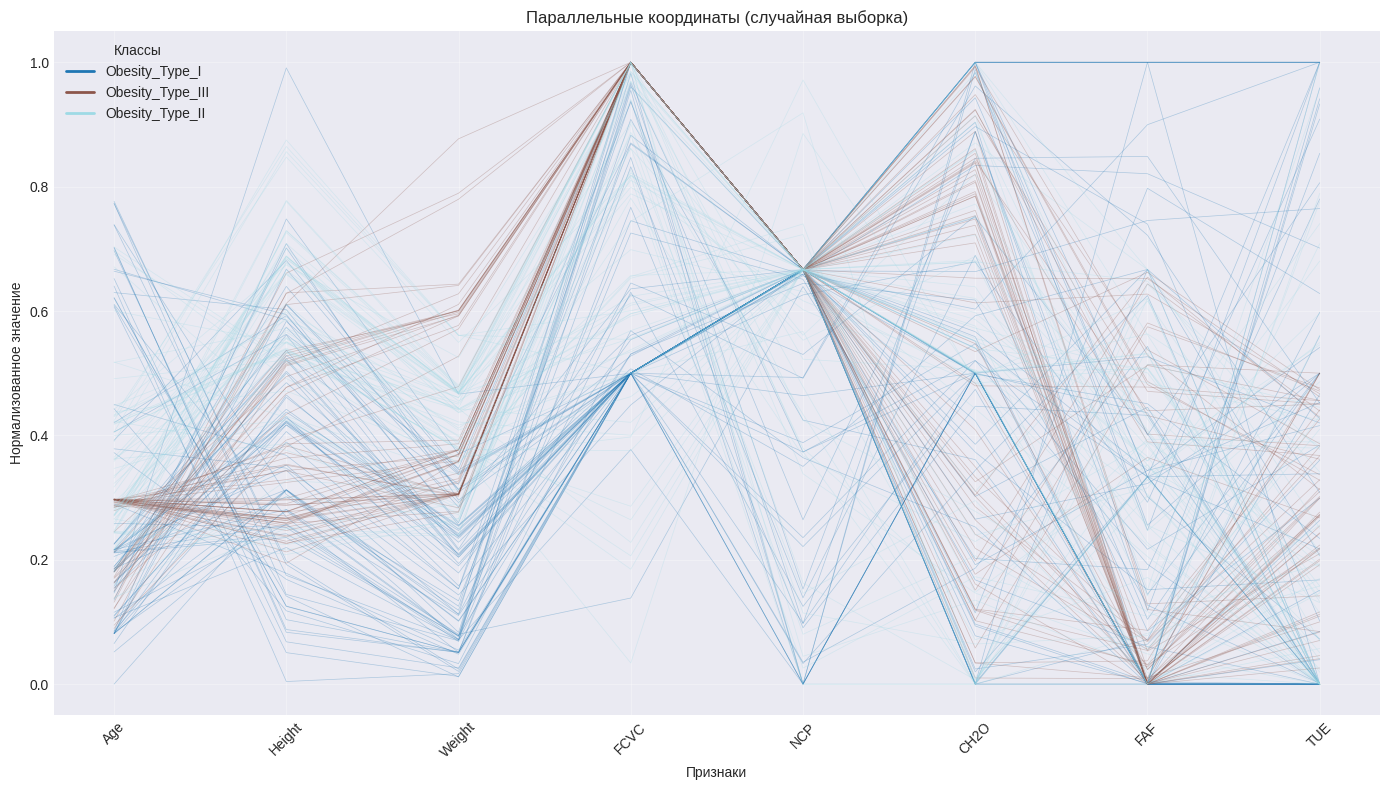


7. Радар-чарты по классам


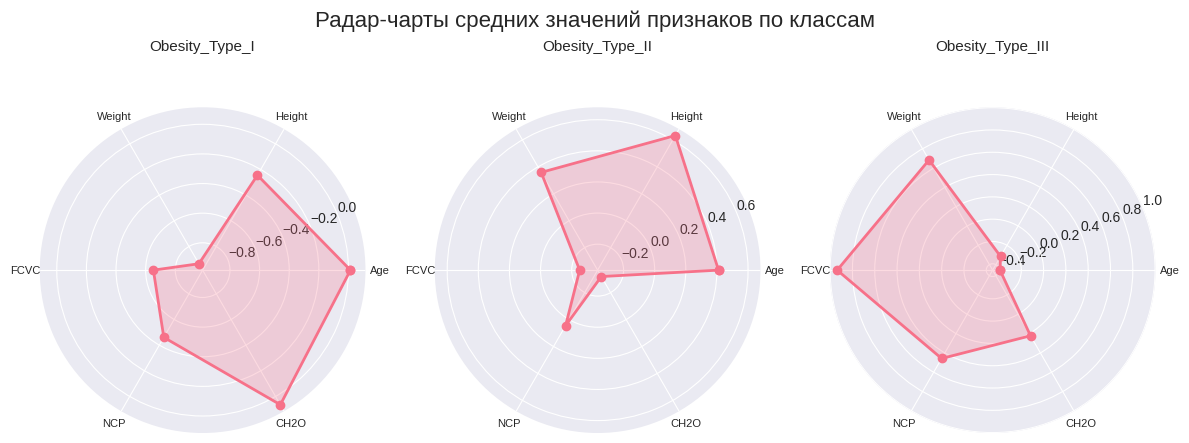


9. Сравнение методов уменьшения размерности
  Применяем PCA...
  Применяем t-SNE...
  Применяем MDS...
  Применяем Isomap...
  Применяем UMAP...


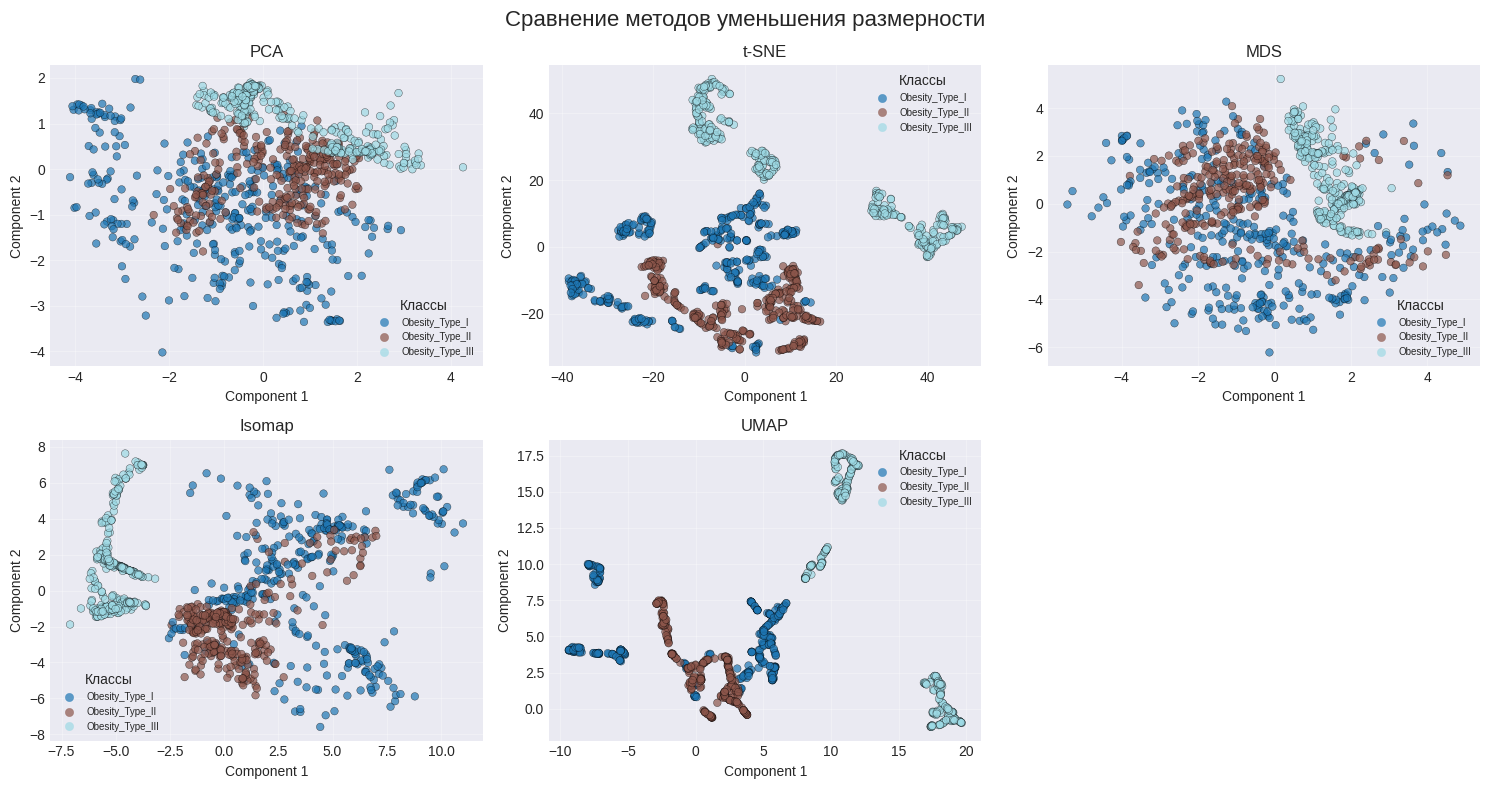


5. Визуализация UMAP


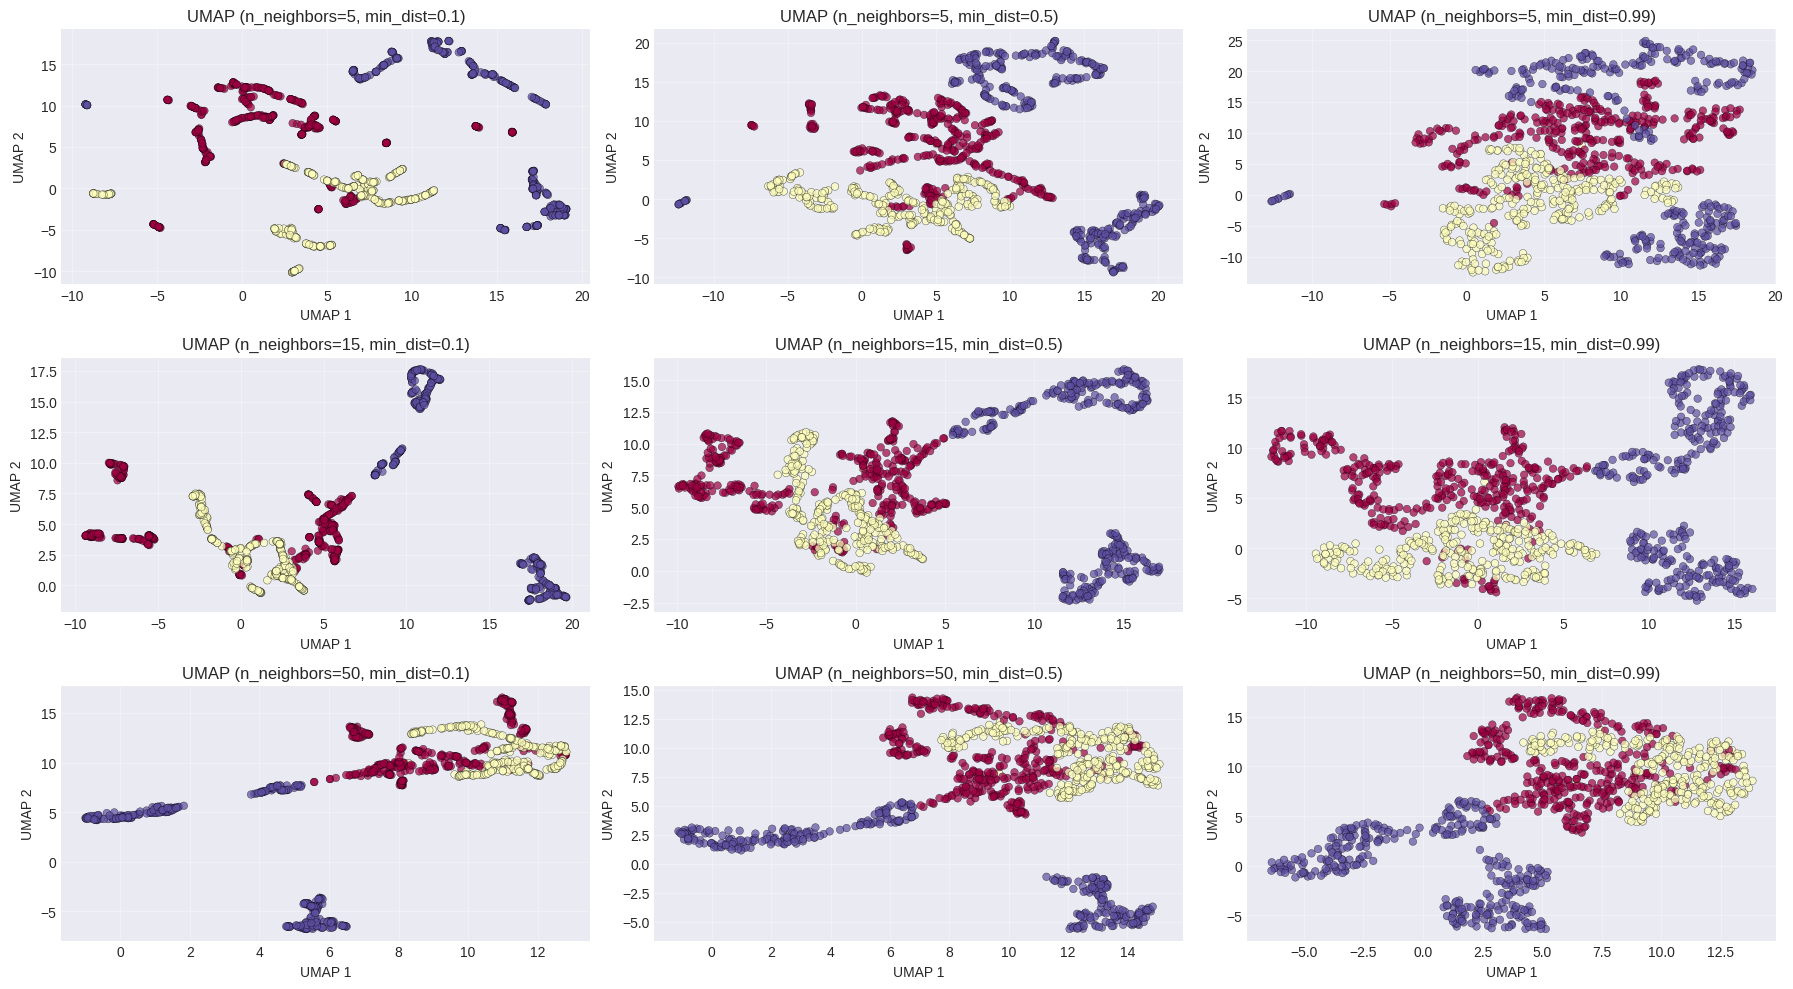


8. Интерактивная 3D визуализация (откроется в браузере)
  График сохранен в файл: interactive_3d_plot.html



ВИЗУАЛИЗАЦИЯ ЗАВЕРШЕНА


In [10]:
 # Инициализация визуализатора
visualizer = HighDimVisualizer(random_state=67)

X, y, feature_names = visualizer.load_dataset(n_classes=3)

# Базовая информация о данных
print(f"\nИнформация о данных:")
print(f"  Размер: {X.shape}")
print(f"  Количество классов: {len(np.unique(y))}")
print(f"  Количество признаков: {X.shape[1]}")
print(f"  Минимум: {X.min():.3f}, Максимум: {X.max():.3f}")
print(f"  Среднее: {X.mean():.3f}, Стандартное отклонение: {X.std():.3f}")

# Запуск визуализации
visualizer.run_full_visualization(X, y, feature_names)